# Emotion Classification: TF-IDF Baseline vs RNN, LSTM, GRU and BiGRU

**Team:** M Anirudh (23STUCHH010748), V Babu(23STUCHH010791), A Thanay (23STUCHH010726).
SECTION B
**Goal:** classify short English texts into 6 emotions (*sadness, joy, love, anger, fear, surprise*) and find out which kind of model works best, and why.

**Dataset:** [`dair-ai/emotion`](https://huggingface.co/datasets/dair-ai/emotion), 16,000 training / 2,000 validation / 2,000 test texts (tweets).

**Plan**
1. Look at the data
2. Preprocess the text (one cleaning function used for training *and* prediction)
3. Build a simple baseline: TF-IDF + logistic regression
4. Train four neural models: SimpleRNN, LSTM, GRU, Bidirectional GRU
5. Test one hypothesis: does padding hurt plain RNNs unless we mask it?
6. Compare everything fairly and analyze the errors of the best model

**Fair-comparison rules used in this notebook**
- Every model sees the same data and the same preprocessing.
- The **validation set** is used for early stopping and for picking the best neural model.
- The **test set** is only used to report final numbers. It never influences any choice.



## 1. Setup

In [2]:

!pip install -q datasets

import os, re, json, time, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, LSTM, GRU, Bidirectional, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.utils import class_weight

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
sns.set_theme(style="whitegrid")
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


In [3]:

DATA_SOURCE = os.environ.get("DATA_SOURCE", "hf")  # "hf" = download from Hugging Face, "csv" = read local files
CSV_DIR = os.environ.get("CSV_DIR", "data")        # for "csv": folder with train.csv, validation.csv, test.csv (columns: text,label)
EPOCHS = int(os.environ.get("EPOCHS", 20))         # upper limit; early stopping usually stops sooner
MAX_WORDS = 10000                                  # vocabulary size (includes PAD=0 and UNK=1)
MAX_LEN = 50                                       # words kept per text
# --------------------------------------------------------------------------------

LABELS = ["sadness", "joy", "love", "anger", "fear", "surprise"]

if DATA_SOURCE == "hf":
    from datasets import load_dataset
    ds = load_dataset("dair-ai/emotion")
    LABELS = ds["train"].features["label"].names
    df_train, df_val, df_test = [
        pd.DataFrame({"text": ds[s]["text"], "label": ds[s]["label"]})
        for s in ("train", "validation", "test")
    ]
else:
    df_train, df_val, df_test = [pd.read_csv(f"{CSV_DIR}/{s}.csv") for s in ("train", "validation", "test")]

print("Labels:", LABELS)
print("Sizes: train", len(df_train), "| validation", len(df_val), "| test", len(df_test))

README.md:   0%|          | 0.00/9.05k [00:00<?, ?B/s]

split/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

split/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  127kB            

split/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

split/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  129kB            

split/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Labels: ['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']
Sizes: train 16000 | validation 2000 | test 2000


## 2. Look at the data

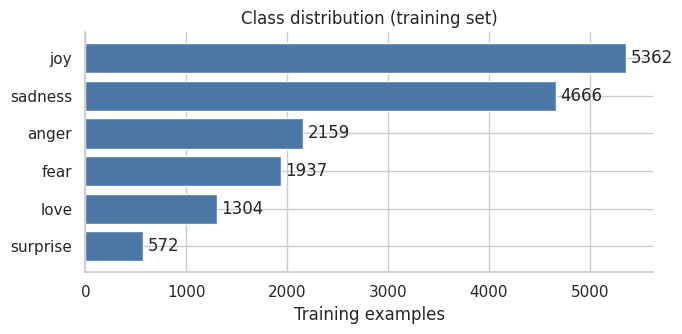

Words per text:
count    16000.0
mean        19.2
std         11.0
min          2.0
25%         11.0
50%         17.0
75%         25.0
max         66.0


,text,label
8756,ive made it through a week i just feel beaten down,sadness
4660,i feel this strategy is worthwhile,joy
6095,i feel so worthless and weak what does he have to say that s what i want to find out,sadness
304,i feel clever nov,joy
8241,im moved in ive been feeling kind of gloomy,sadness
9577,i allowed myself to feel the really shitty feelings while i was running because a the endorphins were flowing so it ...,sadness


In [4]:
counts = df_train["label"].map(lambda i: LABELS[i]).value_counts()

fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(counts.index[::-1], counts.values[::-1], color="#4C78A8")
ax.bar_label(bars, padding=3)
ax.set_xlabel("Training examples")
ax.set_title("Class distribution (training set)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

lengths = df_train["text"].str.split().str.len()
print("Words per text:")
print(lengths.describe().round(1).to_string())

pd.set_option("display.max_colwidth", 120)
sample = df_train.sample(6, random_state=SEED).copy()
sample["label"] = sample["label"].map(lambda i: LABELS[i])
display(sample)

**What to notice**
- The classes are **imbalanced** (a few emotions have many more examples than others). So plain *accuracy* can look good while rare classes are handled badly. We therefore report **macro-F1** too: the average F1 over the six classes, each class counting equally.
- To soften the imbalance during training we use **class weights**: mistakes on rare classes cost more.
- Texts are short and already lowercase with little punctuation.

## 3. Preprocess the text

We build the tokenizer ourselves (a few lines, easy to explain):

1. `clean()` lowercases and removes punctuation.
2. The vocabulary is the 9,998 most frequent training words. Id `0` is reserved for **padding** and id `1` for **unknown words**.
3. Every text becomes a list of word ids, cut or padded with zeros to exactly `MAX_LEN` words.

The **same `clean()` and `encode()`** are used later for new sentences, so training and prediction always see text in the same format.

In [5]:
def clean(text):
    text = text.lower()
    text = text.replace("'", "")
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()


counter = Counter(w for t in df_train["text"] for w in clean(t).split())
vocab = {w: i + 2 for i, (w, _) in enumerate(counter.most_common(MAX_WORDS - 2))}


def encode(texts):
    X = np.zeros((len(texts), MAX_LEN), dtype="int32")      # 0 = padding
    for row, t in enumerate(texts):
        ids = [vocab.get(w, 1) for w in clean(t).split()][:MAX_LEN]   # 1 = unknown word
        X[row, :len(ids)] = ids
    return X


X_train, X_val, X_test = (encode(d["text"].tolist()) for d in (df_train, df_val, df_test))
y_train, y_val, y_test = (d["label"].to_numpy() for d in (df_train, df_val, df_test))

val_tokens = [w for t in df_val["text"] for w in clean(t).split()]
print("Unique training words:", len(counter), "| vocabulary kept:", len(vocab))
print(f"Texts longer than {MAX_LEN} words (get cut): {(lengths > MAX_LEN).mean():.2%}")
print(f"Unknown-word rate on validation tokens: {np.mean([w not in vocab for w in val_tokens]):.2%}")
print()
print("Example:", df_train["text"][0])
print("Encoded:", X_train[0][:15], "...")

weights = class_weight.compute_class_weight("balanced", classes=np.arange(len(LABELS)), y=y_train)
class_weight_dict = dict(enumerate(weights))
print()
print("Class weights:", {LABELS[k]: round(float(v), 2) for k, v in class_weight_dict.items()})

Unique training words: 15212 | vocabulary kept: 9998
Texts longer than 50 words (get cut): 1.33%
Unknown-word rate on validation tokens: 3.60%

Example: i didnt feel humiliated
Encoded: [  2 139   3 679   0   0   0   0   0   0   0   0   0   0   0] ...

Class weights: {'sadness': 0.57, 'joy': 0.5, 'love': 2.04, 'anger': 1.24, 'fear': 1.38, 'surprise': 4.66}


## 4. Baseline: TF-IDF + logistic regression

Before using neural networks we need something simple to beat. TF-IDF turns each text into a vector of word (and word-pair) weights, and logistic regression learns which words point to which emotion. If a deep model cannot clearly beat this, the extra complexity is not worth it.

In [6]:
results, histories, test_preds, trained = {}, {}, {}, {}


def record(name, kind, val_pred, test_pred, seconds, params):
    results[name] = {
        "Type": kind,
        "Val accuracy": accuracy_score(y_val, val_pred),
        "Test accuracy": accuracy_score(y_test, test_pred),
        "Test macro-F1": f1_score(y_test, test_pred, average="macro"),
        "Parameters": int(params),
        "Train time (s)": round(seconds, 1),
    }
    test_preds[name] = test_pred


t0 = time.time()
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
Xtr = tfidf.fit_transform(df_train["text"].map(clean))
Xva = tfidf.transform(df_val["text"].map(clean))
Xte = tfidf.transform(df_test["text"].map(clean))

logreg = LogisticRegression(max_iter=2000, C=5, class_weight="balanced")
logreg.fit(Xtr, y_train)
secs = time.time() - t0

record("TF-IDF + LogReg", "Baseline", logreg.predict(Xva), logreg.predict(Xte), secs, logreg.coef_.size)
r = results["TF-IDF + LogReg"]
print(f"Baseline: val acc {r['Val accuracy']:.3f} | test acc {r['Test accuracy']:.3f} | test macro-F1 {r['Test macro-F1']:.3f} | {secs:.0f}s")

Baseline: val acc 0.889 | test acc 0.882 | test macro-F1 0.837 | 17s


## 5. Neural models

All four models share the same simple structure, so the only thing that changes is the recurrent layer:

`Embedding → recurrent layer (64 units) → Dropout → Dense(6, softmax)`

| Model | Recurrent layer | Idea |
|---|---|---|
| SimpleRNN | `SimpleRNN` | Reads words left to right, keeps a hidden state. Struggles to remember far back (vanishing gradients). |
| LSTM | `LSTM` | Adds gates that decide what to remember and forget. |
| GRU | `GRU` | A lighter version of the LSTM with fewer gates. |
| BiGRU | `Bidirectional(GRU)` | Reads the text forwards *and* backwards, so every word sees context from both sides. |

**Padding mask:** texts are padded with zeros at the end. With `mask_zero=True` the model skips those padding positions. Without it, a one-direction RNN has to read many meaningless zeros *after* the real words, which can wash out what it learned. Section 6 tests this directly.

In [7]:
def build_model(cell, bidirectional=False, mask=True, units=64, emb_dim=128, dropout=0.4):
    cells = {"rnn": SimpleRNN, "lstm": LSTM, "gru": GRU}
    layer = cells[cell](units)
    if bidirectional:
        layer = Bidirectional(layer)
    model = Sequential([
        Input(shape=(MAX_LEN,)),
        Embedding(MAX_WORDS, emb_dim, mask_zero=mask),
        layer,
        Dropout(dropout),
        Dense(len(LABELS), activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def train_and_record(name, model, kind="Neural", batch_size=64):
    # Early stopping watches the VALIDATION loss and restores the best weights.
    es = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    t0 = time.time()
    hist = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS, batch_size=batch_size,
        class_weight=class_weight_dict, callbacks=[es], verbose=2,
    )
    secs = time.time() - t0
    val_pred = model.predict(X_val, verbose=0).argmax(axis=1)
    test_pred = model.predict(X_test, verbose=0).argmax(axis=1)
    record(name, kind, val_pred, test_pred, secs, model.count_params())
    histories[name] = hist.history
    trained[name] = model
    r = results[name]
    print(f"\n{name}: val acc {r['Val accuracy']:.3f} | test acc {r['Test accuracy']:.3f} | test macro-F1 {r['Test macro-F1']:.3f} | {secs:.0f}s")

### 5.1 SimpleRNN

In [8]:
tf.keras.utils.set_random_seed(SEED)
model = build_model("rnn")
model.summary()
train_and_record("SimpleRNN", model)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 128)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,292,742 (4.93 MB)

 Trainable params: 1,292,742 (4.93 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
250/250 - 9s - 37ms/step - accuracy: 0.2268 - loss: 1.7288 - val_accuracy: 0.3675 - val_loss: 1.5607
Epoch 2/20
250/250 - 2s - 8ms/step - accuracy: 0.6428 - loss: 0.9194 - val_accuracy: 0.7820 - val_loss: 0.6792
Epoch 3/20
250/250 - 2s - 8ms/step - accuracy: 0.8696 - loss: 0.3709 - val_accuracy: 0.7775 - val_loss: 0.6910
Epoch 4/20
250/250 - 2s - 6ms/step - accuracy: 0.9280 - loss: 0.2183 - val_accuracy: 0.7390 - val_loss: 0.9378
Epoch 5/20
250/250 - 3s - 10ms/step - accuracy: 0.9389 - loss: 0.1809 - val_accuracy: 0.7930 - val_loss: 0.6913

SimpleRNN: val acc 0.782 | test acc 0.780 | test macro-F1 0.723 | 17s


### 5.2 LSTM

In [9]:
tf.keras.utils.set_random_seed(SEED)
model = build_model("lstm")
train_and_record("LSTM", model)

Epoch 1/20
250/250 - 8s - 33ms/step - accuracy: 0.5031 - loss: 1.4148 - val_accuracy: 0.8215 - val_loss: 0.6567
Epoch 2/20
250/250 - 2s - 7ms/step - accuracy: 0.8964 - loss: 0.3483 - val_accuracy: 0.8840 - val_loss: 0.4177
Epoch 3/20
250/250 - 2s - 7ms/step - accuracy: 0.9404 - loss: 0.1762 - val_accuracy: 0.9045 - val_loss: 0.3405
Epoch 4/20
250/250 - 2s - 7ms/step - accuracy: 0.9615 - loss: 0.1106 - val_accuracy: 0.9100 - val_loss: 0.3268
Epoch 5/20
250/250 - 2s - 7ms/step - accuracy: 0.9684 - loss: 0.0861 - val_accuracy: 0.9085 - val_loss: 0.3175
Epoch 6/20
250/250 - 2s - 10ms/step - accuracy: 0.9772 - loss: 0.0621 - val_accuracy: 0.9105 - val_loss: 0.3280
Epoch 7/20
250/250 - 2s - 9ms/step - accuracy: 0.9818 - loss: 0.0578 - val_accuracy: 0.8965 - val_loss: 0.3798
Epoch 8/20
250/250 - 2s - 7ms/step - accuracy: 0.9490 - loss: 0.1420 - val_accuracy: 0.8955 - val_loss: 0.3818

LSTM: val acc 0.908 | test acc 0.908 | test macro-F1 0.871 | 22s


### 5.3 GRU

In [10]:
tf.keras.utils.set_random_seed(SEED)
model = build_model("gru")
train_and_record("GRU", model)

Epoch 1/20
250/250 - 3s - 14ms/step - accuracy: 0.4790 - loss: 1.4748 - val_accuracy: 0.8460 - val_loss: 0.5455
Epoch 2/20
250/250 - 2s - 7ms/step - accuracy: 0.9026 - loss: 0.2958 - val_accuracy: 0.9175 - val_loss: 0.2518
Epoch 3/20
250/250 - 2s - 10ms/step - accuracy: 0.9460 - loss: 0.1415 - val_accuracy: 0.9210 - val_loss: 0.2456
Epoch 4/20
250/250 - 2s - 9ms/step - accuracy: 0.9617 - loss: 0.1009 - val_accuracy: 0.9235 - val_loss: 0.2514
Epoch 5/20
250/250 - 3s - 11ms/step - accuracy: 0.9709 - loss: 0.0723 - val_accuracy: 0.9160 - val_loss: 0.2923
Epoch 6/20
250/250 - 2s - 7ms/step - accuracy: 0.9762 - loss: 0.0625 - val_accuracy: 0.9175 - val_loss: 0.2681

GRU: val acc 0.921 | test acc 0.920 | test macro-F1 0.879 | 15s


### 5.4 Bidirectional GRU (BiGRU)

In [11]:
tf.keras.utils.set_random_seed(SEED)
model = build_model("gru", bidirectional=True)
train_and_record("BiGRU", model)

Epoch 1/20
250/250 - 5s - 20ms/step - accuracy: 0.4531 - loss: 1.3882 - val_accuracy: 0.8320 - val_loss: 0.5560
Epoch 2/20
250/250 - 4s - 17ms/step - accuracy: 0.9020 - loss: 0.2693 - val_accuracy: 0.9100 - val_loss: 0.2758
Epoch 3/20
250/250 - 2s - 10ms/step - accuracy: 0.9447 - loss: 0.1387 - val_accuracy: 0.9115 - val_loss: 0.2910
Epoch 4/20
250/250 - 3s - 10ms/step - accuracy: 0.9609 - loss: 0.0945 - val_accuracy: 0.9100 - val_loss: 0.3048
Epoch 5/20
250/250 - 3s - 12ms/step - accuracy: 0.9728 - loss: 0.0696 - val_accuracy: 0.9170 - val_loss: 0.2898

BiGRU: val acc 0.910 | test acc 0.902 | test macro-F1 0.861 | 19s


## 6. Experiment: does the padding mask matter?

**Hypothesis:** an LSTM that is *not* told to ignore the padding zeros will perform much worse than the same LSTM with the mask, because its final state is dominated by padding.

We train the LSTM again with `mask=False` and change nothing else.

In [12]:
tf.keras.utils.set_random_seed(SEED)
model = build_model("lstm", mask=False)
train_and_record("LSTM (no mask)", model, kind="Ablation")

Epoch 1/20
250/250 - 3s - 12ms/step - accuracy: 0.1682 - loss: 1.7945 - val_accuracy: 0.2740 - val_loss: 1.7893
Epoch 2/20
250/250 - 2s - 7ms/step - accuracy: 0.1809 - loss: 1.7924 - val_accuracy: 0.0435 - val_loss: 1.7885
Epoch 3/20
250/250 - 2s - 7ms/step - accuracy: 0.2080 - loss: 1.7916 - val_accuracy: 0.0625 - val_loss: 1.8031
Epoch 4/20
250/250 - 2s - 9ms/step - accuracy: 0.1673 - loss: 1.7979 - val_accuracy: 0.1375 - val_loss: 1.7936
Epoch 5/20
250/250 - 2s - 9ms/step - accuracy: 0.1710 - loss: 1.7900 - val_accuracy: 0.1130 - val_loss: 1.7967

LSTM (no mask): val acc 0.043 | test acc 0.039 | test macro-F1 0.021 | 11s


## 7. Compare all models

Remember: the *Val accuracy* column is what we use to choose a model. The *Test* columns are the final report.

,Type,Val accuracy,Test accuracy,Test macro-F1,Parameters,Train time (s)
GRU,Neural,0.921,0.920,0.879,1317638,14.8
LSTM,Neural,0.908,0.908,0.871,1329798,22.2
BiGRU,Neural,0.910,0.902,0.861,1355270,19.2
TF-IDF + LogReg,Baseline,0.889,0.882,0.837,197970,16.8
SimpleRNN,Neural,0.782,0.780,0.723,1292742,17.3
LSTM (no mask),Ablation,0.044,0.039,0.021,1329798,11.5


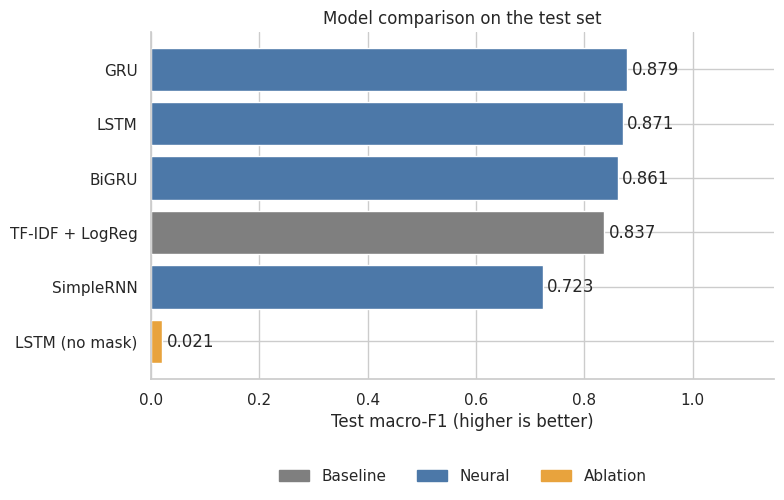

In [13]:
table = pd.DataFrame.from_dict(results, orient="index").sort_values("Test macro-F1", ascending=False)
display(table.round(3))
table.round(4).to_csv("results.csv")

palette = {"Baseline": "#7F7F7F", "Neural": "#4C78A8", "Ablation": "#E8A33D"}
order = table.sort_values("Test macro-F1")

fig, ax = plt.subplots(figsize=(8, 0.55 * len(order) + 2.0))
bars = ax.barh(order.index, order["Test macro-F1"], color=[palette[t] for t in order["Type"]])
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_xlim(0, 1.15)
ax.set_xlabel("Test macro-F1 (higher is better)")
ax.set_title("Model comparison on the test set")
ax.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()], palette.keys(),
          loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

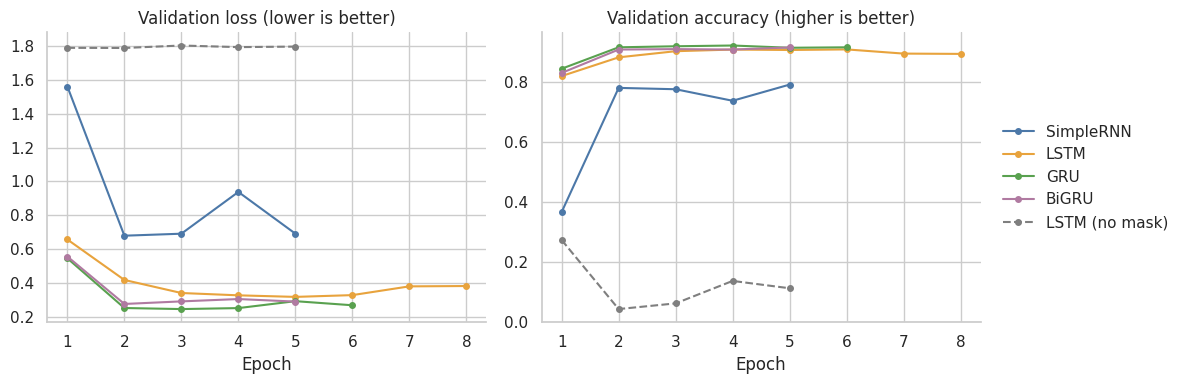

In [14]:
from matplotlib.ticker import MaxNLocator

line_colors = {"SimpleRNN": "#4C78A8", "LSTM": "#E8A33D", "GRU": "#59A14F",
               "BiGRU": "#B07AA1", "LSTM (no mask)": "#7F7F7F"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, h in histories.items():
    style = "--" if name == "LSTM (no mask)" else "-"
    axes[0].plot(range(1, len(h["val_loss"]) + 1), h["val_loss"], style, marker="o", ms=4,
                 color=line_colors[name], label=name)
    axes[1].plot(range(1, len(h["val_accuracy"]) + 1), h["val_accuracy"], style, marker="o", ms=4,
                 color=line_colors[name], label=name)
axes[0].set_title("Validation loss (lower is better)")
axes[1].set_title("Validation accuracy (higher is better)")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.spines[["top", "right"]].set_visible(False)
axes[1].legend(frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()

**Questions to answer in your report (use your own numbers):**
1. Which model has the best test macro-F1? Does it also have the best validation accuracy?
2. Did LSTM and GRU beat SimpleRNN? Why might that be?
3. Did reading in both directions (BiGRU) help compared with GRU?
4. Did the neural models clearly beat the TF-IDF baseline? Is the extra training time worth it?
5. What happened when the mask was removed? Does it support the hypothesis?

## 8. Analyze the best neural model

The best neural model is chosen by **validation** accuracy (not test), so the test set stays untouched until reporting.

In [15]:
neural = table[table["Type"] == "Neural"]
best_name = neural["Val accuracy"].idxmax()
best_pred = test_preds[best_name]
print("Best neural model (by validation accuracy):", best_name)
print()
print(classification_report(y_test, best_pred, target_names=LABELS, digits=3, zero_division=0))

Best neural model (by validation accuracy): GRU

              precision    recall  f1-score   support

     sadness      0.989     0.940     0.964       581
         joy      0.977     0.909     0.942       695
        love      0.753     0.899     0.819       159
       anger      0.912     0.942     0.927       275
        fear      0.855     0.897     0.876       224
    surprise      0.641     0.894     0.747        66

    accuracy                          0.920      2000
   macro avg      0.855     0.914     0.879      2000
weighted avg      0.929     0.920     0.923      2000



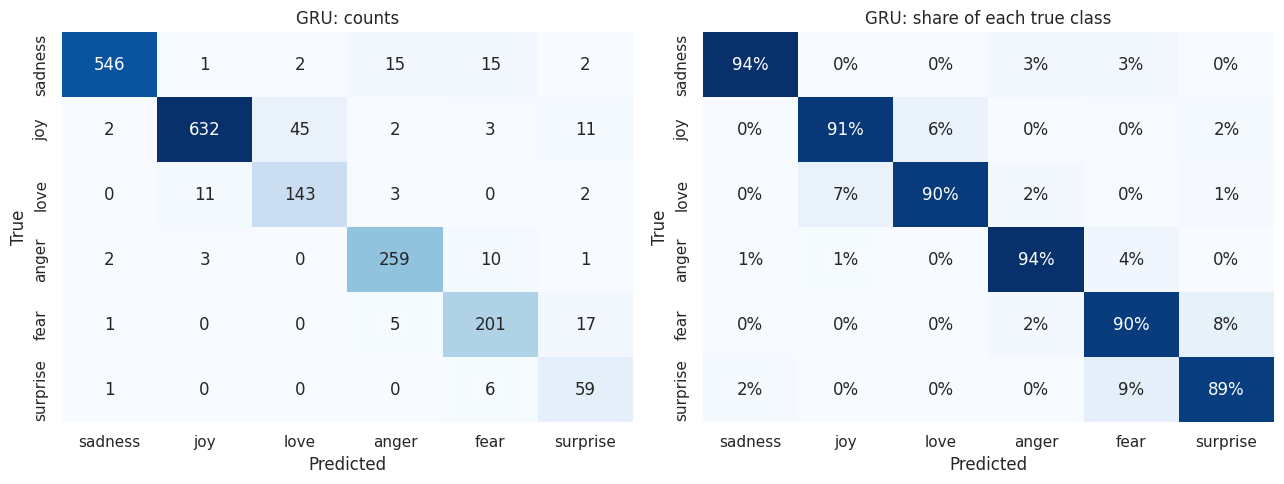

In [16]:
cm = confusion_matrix(y_test, best_pred, labels=np.arange(len(LABELS)))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=axes[0], cbar=False)
axes[0].set_title(f"{best_name}: counts")
sns.heatmap(cm_norm, annot=True, fmt=".0%", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=axes[1], cbar=False)
axes[1].set_title(f"{best_name}: share of each true class")
for ax in axes:
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.show()

### Error analysis

Numbers hide *why* a model fails. Below are the most-confused label pairs and the mistakes the model was most confident about.

In [17]:
probs = trained[best_name].predict(X_test, verbose=0)
errors = df_test.assign(
    true=[LABELS[i] for i in y_test],
    predicted=[LABELS[i] for i in best_pred],
    confidence=probs.max(axis=1).round(2),
)
errors = errors[errors["true"] != errors["predicted"]]
print(f"{len(errors)} of {len(df_test)} test texts misclassified\n")

print("Most common confusions (true -> predicted):")
print(errors.groupby(["true", "predicted"]).size().sort_values(ascending=False).head(6).to_string())
print()
print("Most confident mistakes:")
display(errors.sort_values("confidence", ascending=False)[["text", "true", "predicted", "confidence"]].head(10))

160 of 2000 test texts misclassified

Most common confusions (true -> predicted):
true     predicted
joy      love         45
fear     surprise     17
sadness  anger        15
         fear         15
joy      surprise     11
love     joy          11

Most confident mistakes:


,text,true,predicted,confidence
1026,i have not conducted a survey but it is quite likely that many of them feel as assaulted by onel s demons and other ...,sadness,fear,1.00
426,i feel unprotected a class post count link href http reprogramming in process,sadness,fear,1.00
62,i spent wandering around still kinda dazed and not feeling particularly sociable but because id been in hiding for a...,joy,surprise,0.99
100,i feel needy but comfortable with it i feel vulnerable but secure i feel the urge to cum hard but i get no relief,sadness,fear,0.99
1037,i always feel so helpless during times of disaster but i feel a little better knowing that even a few dollars can ma...,sadness,fear,0.99
939,i found myself being amazed at how mid s f would feel a tad cool as if perhaps a sweatshirt wouldve been a good idea,joy,surprise,0.99
262,i realized what i am passionate about helping women feel accepted and appreciated,joy,love,0.99
1593,i suppose we all feel a little inhibited when it comes to picking up the phone and calling someone we re not very cl...,sadness,fear,0.99
1341,im feeling so embarrassed frightened that i wouldve smashed the window and slid in dukes of hazzard style if it woul...,sadness,fear,0.99
1860,i feel so dirty but after spending a day at the mk show me and a buddy decided we would get the two player starter b...,sadness,love,0.99


**Things to discuss:** Are the confused pairs emotions that are close in meaning (for example *joy* and *love*)? Are some of the "mistakes" actually reasonable, or are the labels questionable? The dataset's labels were created automatically from hashtags, so some are noisy.

## 9. Try it on new sentences

This uses the same `clean()` and `encode()` as training. Keep one limitation in mind: the training texts are short, lowercase, "i feel ..." style tweets, so very differently written sentences can fool the model. Testing that honestly is part of a good report.

In [18]:
def predict_emotion(texts, name=None):
    model = trained[name or best_name]
    probs = model.predict(encode(texts), verbose=0)
    for text, p in zip(texts, probs):
        first, second = np.argsort(p)[::-1][:2]
        print(f"{text!r}\n   -> {LABELS[first]} ({p[first]:.0%}), then {LABELS[second]} ({p[second]:.0%})")


predict_emotion([
    "i feel so alone and hopeless today",
    "i am furious that they cancelled the trip at the last minute",
    "i feel terrified when walking down dark alleyways alone",
    "i was shocked and completely surprised by the unexpected gift",
    "I can't believe how happy I am right now, this is amazing!",
    "the meeting is at three o'clock tomorrow",
])

'i feel so alone and hopeless today'
   -> sadness (100%), then anger (0%)
'i am furious that they cancelled the trip at the last minute'
   -> anger (99%), then love (0%)
'i feel terrified when walking down dark alleyways alone'
   -> fear (100%), then sadness (0%)
'i was shocked and completely surprised by the unexpected gift'
   -> surprise (99%), then fear (0%)
"I can't believe how happy I am right now, this is amazing!"
   -> joy (59%), then surprise (40%)
"the meeting is at three o'clock tomorrow"
   -> fear (50%), then anger (39%)


## 10. Save the model (optional)

Saves the best model, the vocabulary and the label names, so the model can be loaded later (for example behind a small web app) without retraining.

In [19]:
os.makedirs("artifacts", exist_ok=True)
trained[best_name].save("artifacts/best_model.keras")
with open("artifacts/vocab.json", "w") as f:
    json.dump(vocab, f)
with open("artifacts/labels.json", "w") as f:
    json.dump(LABELS, f)
print("Saved to ./artifacts:", os.listdir("artifacts"))

Saved to ./artifacts: ['labels.json', 'best_model.keras', 'vocab.json']


In [21]:
for n, m in trained.items():
    m.save(f"artifacts/{n}.keras")

In [25]:
predict_emotion(["I love apple"])


'I love apple'
   -> love (37%), then anger (27%)


In [26]:
predict_emotion(["I love playing cricket"])

'I love playing cricket'
   -> joy (60%), then love (23%)
